# 04 - Skytrax ile Dış Doğrulama (Turkish Airlines dahil)
Kaggle veri setinin asıl kaynağı belirsiz olduğu için bulgular, kaynağı belli **gerçek yolcu
yorumlarıyla** (airlinequality.com, Skytrax) test edilir.

- Hedef: `recommended` (tavsiye eder mi) → memnuniyet vekili
- `overall_rating` kullanılmaz: tavsiye ile neredeyse aynı bilgi (**hedef sızıntısı**)
- Turkish Airlines yorumları eğitimden çıkarılır; model diğer havayollarında öğrenip THY'de test edilir.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src import config as C
from src import skytrax
from src import visualization as viz

viz.set_style()
pd.set_option("display.max_columns", 30)

In [2]:
sky, info = skytrax.load_clean()
info

{'ham_yorum': 41396,
 'temiz_yorum': 31074,
 'havayolu_sayisi': 294,
 'tarih_araligi': '2011-10 / 2015-08',
 'thy_yorum': 495,
 'tavsiye_orani': np.float64(0.5433),
 'overall_recommended_korelasyon': np.float64(0.8674),
 'eksik_oranlari': {'seat_comfort_rating': 0.186,
  'cabin_staff_rating': 0.186,
  'food_beverages_rating': 0.196,
  'inflight_entertainment_rating': 0.248,
  'value_money_rating': 0.04,
  'ground_service_rating': 0.947,
  'wifi_connectivity_rating': 0.986}}

## 1. Modeller: diğer havayolları ve THY (dış örneklem)

In [3]:
sky_models, sky_res, sky_params, (sky_Xte, thy) = skytrax.train_models(sky)
print(sky_params)
sky_res.round(4)

{'Decision Tree': {'max_depth': 8, 'min_samples_leaf': 10}, 'Random Forest': {'max_depth': None, 'min_samples_leaf': 10}}


,model,accuracy,precision,recall,f1,roc_auc,veri
0,Decision Tree,0.9271,0.9386,0.9261,0.9323,0.9790,diğer havayolları (test)
1,Decision Tree,0.9172,0.9320,0.9288,0.9304,0.9688,Turkish Airlines (dış örneklem)
2,Random Forest,0.9285,0.9390,0.9285,0.9338,0.9812,diğer havayolları (test)
3,Random Forest,0.9192,0.9264,0.9390,0.9327,0.9742,Turkish Airlines (dış örneklem)


## 2. Faktörlerin önemi: Kaggle ile karşılaştırma
Not: İki veri setinde yalnızca dört ortak faktör bulunduğundan karşılaştırma niteldir; istatistiksel bir test yapılmaz.

,feature,mean_abs_shap
0,value_money_rating,0.219592
1,cabin_staff_rating,0.138018
2,seat_comfort_rating,0.081731
3,food_beverages_rating,0.052080
4,inflight_entertainment_rating,0.023315
5,cabin_business,0.002951


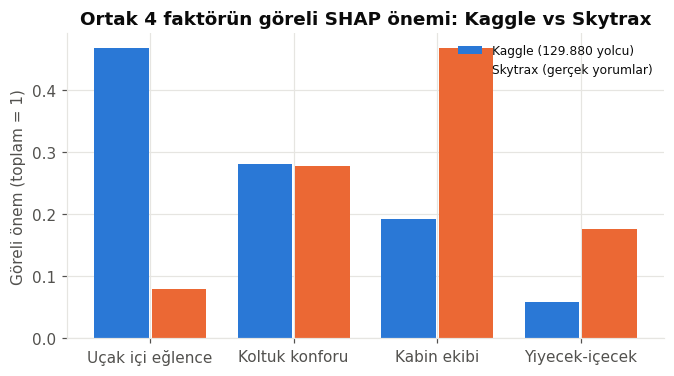

,faktor,skytrax,kaggle,skytrax_sira,kaggle_sira
3,Uçak içi eğlence,0.079,0.468,4,1
0,Koltuk konforu,0.277,0.281,2,2
1,Kabin ekibi,0.468,0.192,1,3
2,Yiyecek-içecek,0.176,0.059,3,4


In [4]:
sky_rank = skytrax.shap_ranking(sky_models["Random Forest"], sky_Xte)
display(sky_rank)
aps_rank = pd.read_csv(C.MET_DIR / "shap_siralama.csv")  # main.py çıktısı
comp = skytrax.compare_with_aps(sky_rank, aps_rank)
skytrax.plot_factor_comparison(comp)
plt.show()
comp.round(3)

## 3. Turkish Airlines profili

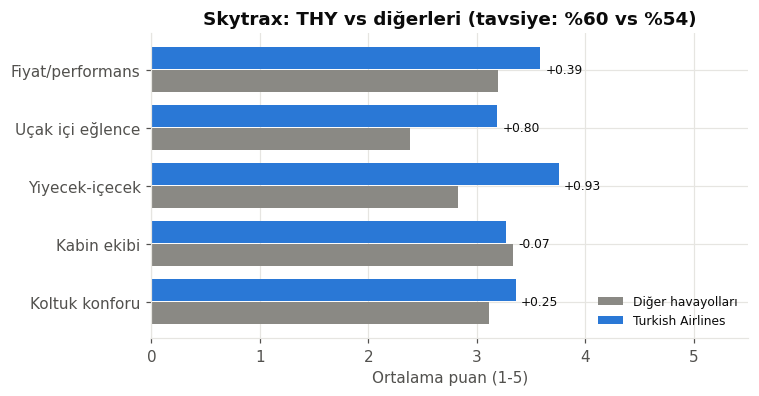

,Diğer havayolları,Turkish Airlines,fark
Koltuk konforu,3.107,3.358,0.250
Kabin ekibi,3.334,3.267,-0.067
Yiyecek-içecek,2.824,3.752,0.927
Uçak içi eğlence,2.380,3.184,0.804
Fiyat/performans,3.196,3.584,0.388
Tavsiye oranı,0.542,0.596,0.054


In [5]:
prof = skytrax.thy_profile(sky)
skytrax.plot_thy_profile(prof)
plt.show()
prof

## Yorum
- Temizlik sonrası 31.074 yorum kaldı (294 havayolu, 2011-10 / 2015-08); bunların 495'i THY.
  `overall_rating`, tavsiye etiketiyle r = 0,867 korelasyonlu olduğu için (hedef sızıntısı) kullanılmadı.
- Diğer havayollarında eğitilen RF, ayrılmış test kümesinde %92,85, eğitimde hiç görmediği THY
  yorumlarında %91,92 doğruluk veriyor (F1 0,9338 / 0,9327; ROC-AUC 0,9812 / 0,9742). Düşüşün
  1 puandan az olması, öğrenilen örüntünün THY'ye taşınabildiğini gösteriyor.
- Skytrax'ta en belirleyici faktör fiyat/performans (ortalama |SHAP| 0,220), ardından kabin ekibi
  (0,138) ve koltuk konforu (0,082).
- Ortak dört faktörün sıralaması büyük ölçüde farklı; yalnızca koltuk konforu iki veri setinde de
  2. sırada (0,277 / 0,281); kabin ekibi Skytrax'ta 1., Kaggle'da 3.; uçak içi eğlence Kaggle'da 1.,
  Skytrax'ta 4. sırada. Karşılaştırma dört faktörle sınırlı olduğundan niteldir.
- THY, yiyecek-içecekte (+0,93) ve uçak içi eğlencede (+0,80) diğer havayollarının belirgin
  üstünde, kabin ekibinde (−0,07) ortalama düzeyde. Tavsiye oranı %59,6 / %54,2.
- Skytrax verisi 2015'e kadardır ve gönüllü yorumlardan oluşur (seçim yanlılığı).